# Operasi Dasar Citra Digital: Deteksi Tepi dengan Sobel

**Nama:** Andre Wijaya  
**NIM:** 24260024

## Tujuan
Menerapkan operator Sobel untuk menonjolkan perubahan intensitas pada foto. Metode ini menghitung gradien pada arah X dan Y lalu menggabungkannya menjadi peta kekuatan tepi. Foto sumber tidak diubah.

## 1. Membaca citra dan memeriksa data
OpenCV membaca kanal warna dalam urutan BGR; untuk Matplotlib gambar dikonversi menjadi RGB.

Nama file      : foto.jpg
Ukuran         : 1200 × 1599 piksel
Jumlah piksel  : 1918800
Bentuk RGB     : (1599, 1200, 3)
Tipe data      : uint8
Rentang gray   : 0 sampai 255


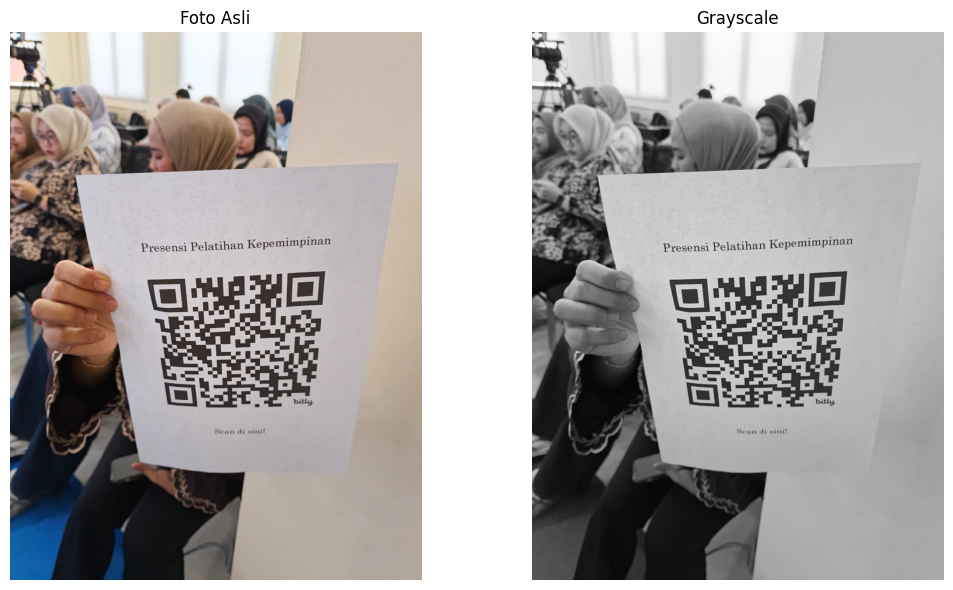

In [6]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PATH_FOTO = Path("foto.jpg")
if not PATH_FOTO.exists():
    raise FileNotFoundError("File foto.jpg tidak ditemukan. Letakkan foto.jpg di folder yang sama dengan notebook.")
gambar_bgr = cv2.imread(str(PATH_FOTO))
if gambar_bgr is None:
    raise ValueError("Gambar tidak dapat dibaca. Periksa file foto.jpg.")

gambar_rgb = cv2.cvtColor(gambar_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(gambar_bgr, cv2.COLOR_BGR2GRAY)
tinggi, lebar = gray.shape

print("Nama file      :", PATH_FOTO.name)
print("Ukuran         :", f"{lebar} × {tinggi} piksel")
print("Jumlah piksel  :", lebar * tinggi)
print("Bentuk RGB     :", gambar_rgb.shape)
print("Tipe data      :", gambar_rgb.dtype)
print("Rentang gray   :", int(gray.min()), "sampai", int(gray.max()))

fig, ax = plt.subplots(1, 2, figsize=(11, 6))
ax[0].imshow(gambar_rgb); ax[0].set_title("Foto Asli"); ax[0].axis("off")
ax[1].imshow(gray, cmap="gray"); ax[1].set_title("Grayscale"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 2. Menghitung gradien Sobel

`Gx` menunjukkan perubahan intensitas pada arah X dan `Gy` pada arah Y. Magnitudo menggabungkan kedua arah tersebut. Data gradien dihitung dalam tipe float agar nilai negatif dan nilai di luar rentang 0–255 tidak terpotong sebelum perhitungan.

In [7]:
gray_float = np.float32(gray)
gx = cv2.Sobel(gray_float, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray_float, cv2.CV_32F, 0, 1, ksize=3)
magnitudo = cv2.magnitude(gx, gy)

# Normalisasi untuk keperluan visualisasi saja.
hasil_sobel = cv2.normalize(magnitudo, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

print("Rentang Gx        :", round(float(gx.min()), 2), "sampai", round(float(gx.max()), 2))
print("Rentang Gy        :", round(float(gy.min()), 2), "sampai", round(float(gy.max()), 2))
print("Rentang magnitudo :", round(float(magnitudo.min()), 2), "sampai", round(float(magnitudo.max()), 2))
print("Rentang tampilan  :", int(hasil_sobel.min()), "sampai", int(hasil_sobel.max()))

Rentang Gx        : -760.0 sampai 764.0
Rentang Gy        : -774.0 sampai 744.0
Rentang magnitudo : 0.0 sampai 774.51
Rentang tampilan  : 0 sampai 254


## 3. Visualisasi hasil
Bagian terang pada peta Sobel menunjukkan perubahan intensitas yang kuat. Tekstur, tulisan, dan detail latar juga dapat muncul sebagai tepi.

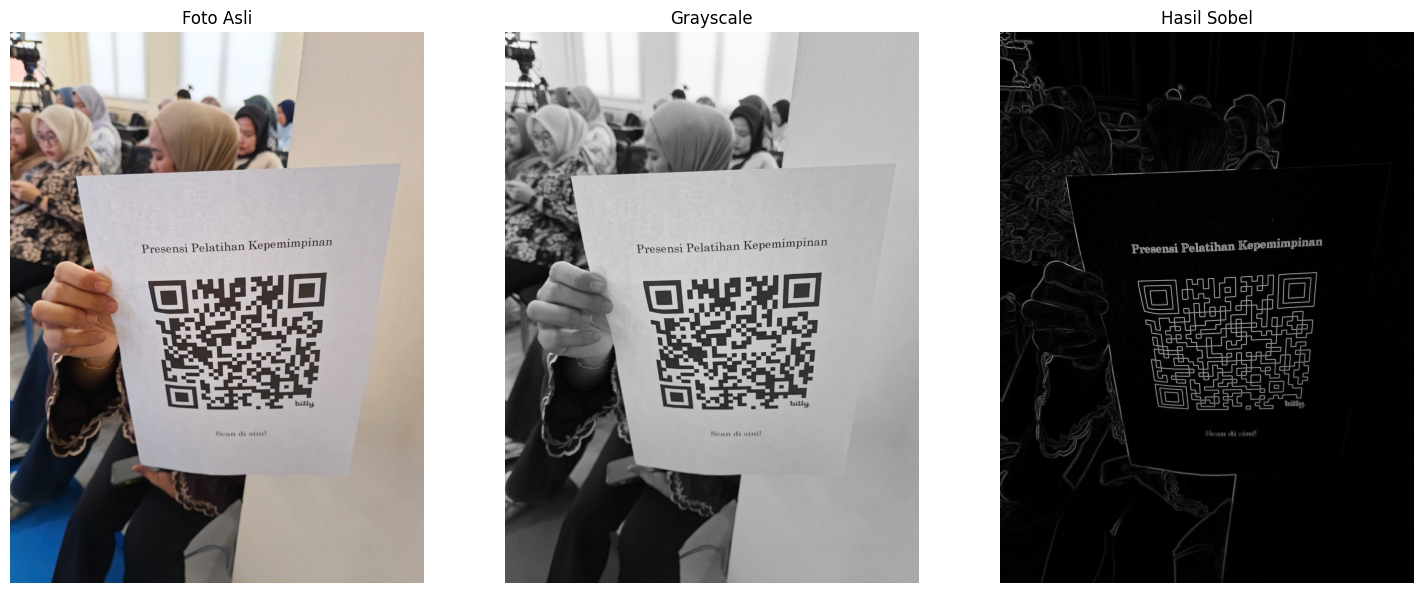

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(gambar_rgb); ax[0].set_title("Foto Asli"); ax[0].axis("off")
ax[1].imshow(gray, cmap="gray"); ax[1].set_title("Grayscale"); ax[1].axis("off")
ax[2].imshow(hasil_sobel, cmap="gray"); ax[2].set_title("Hasil Sobel"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 4. Analisis gradien X dan Y
Visualisasi nilai absolut menunjukkan kekuatan gradien tanpa membedakan tanda positif dan negatif. Tabel berikut merangkum nilai gradien yang dihitung dari foto.

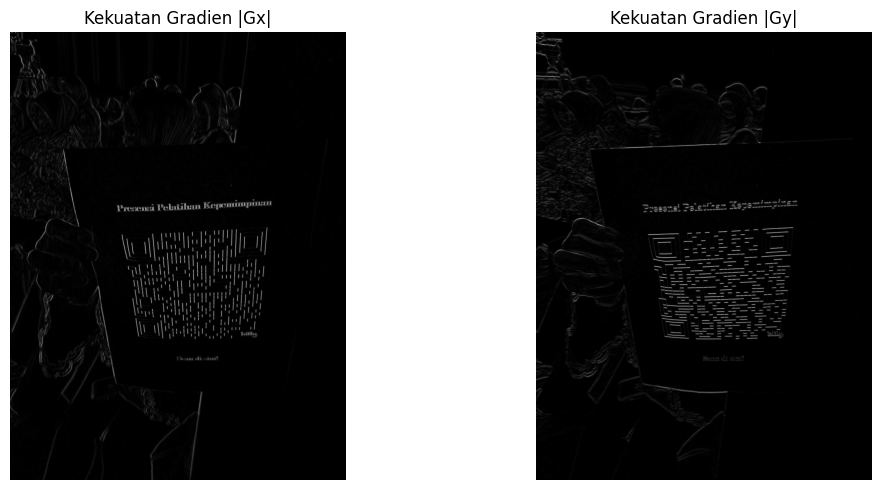

,Komponen,Nilai minimum,Nilai maksimum,Rata-rata absolut
0,Gx,-760.0,764.00,14.99
1,Gy,-774.0,744.00,15.09
2,Magnitudo,0.0,774.51,25.54


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(np.abs(gx), cmap="gray"); ax[0].set_title("Kekuatan Gradien |Gx|"); ax[0].axis("off")
ax[1].imshow(np.abs(gy), cmap="gray"); ax[1].set_title("Kekuatan Gradien |Gy|"); ax[1].axis("off")
plt.tight_layout(); plt.show()

ringkasan = pd.DataFrame([
    {"Komponen": "Gx", "Nilai minimum": float(gx.min()), "Nilai maksimum": float(gx.max()), "Rata-rata absolut": float(np.mean(np.abs(gx)))},
    {"Komponen": "Gy", "Nilai minimum": float(gy.min()), "Nilai maksimum": float(gy.max()), "Rata-rata absolut": float(np.mean(np.abs(gy)))},
    {"Komponen": "Magnitudo", "Nilai minimum": float(magnitudo.min()), "Nilai maksimum": float(magnitudo.max()), "Rata-rata absolut": float(np.mean(magnitudo))}
])
display(ringkasan.round(2))

## 5. Menyimpan hasil
Hasil deteksi tepi dan gradien disimpan di folder `hasil/`. File foto asli tetap aman.

In [10]:
folder_hasil = Path("hasil")
folder_hasil.mkdir(exist_ok=True)
cv2.imwrite(str(folder_hasil / "hasil_sobel.png"), hasil_sobel)
gradien_x_tampil = cv2.normalize(np.abs(gx), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
gradien_y_tampil = cv2.normalize(np.abs(gy), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
cv2.imwrite(str(folder_hasil / "gradien_x.png"), gradien_x_tampil)
cv2.imwrite(str(folder_hasil / "gradien_y.png"), gradien_y_tampil)
print("Hasil disimpan di:", folder_hasil.resolve())
print(" - hasil_sobel.png")
print(" - gradien_x.png")
print(" - gradien_y.png")

Hasil disimpan di: C:\Users\LENOVO\Downloads\Proyek_Andre_Operasi_Dasar_Citra_Digital\Proyek_Operasi_Dasar_Citra_Digital\hasil
 - hasil_sobel.png
 - gradien_x.png
 - gradien_y.png


## 6. Kesimpulan

Operator Sobel menonjolkan perubahan intensitas menggunakan gradien arah X dan Y. Penggabungan gradien menghasilkan peta kekuatan tepi untuk membantu mengamati kontur. Hasil juga dapat menampilkan tekstur, tulisan, dan detail latar, sehingga interpretasi perlu mempertimbangkan konteks foto.